# DDM condition recognition with repeated seeds and six models

This revision aligns with **Article_2026_final.docx**: a 20-sample window and
`HORIZON=0` recognize the current state and estimate a **synthetic normalized risk
indicator**. This is not a calibrated probability of a real failure within a specified
time interval. `HORIZON=5` remains an optional, separate forecasting experiment.

- A fixed 60-device test set is excluded from every fit, scaler, class-weight estimate,
  and validation decision. The other 240 devices are split into 204 training and 36
  validation devices for each seed.
- Five repeats by default, adjustable to ten. Every model uses the same split per seed.
- LSTM, GRU, 1D-CNN, MLP, Random Forest, and XGBoost are evaluated on both outputs.
- All checkpoints, histories, predictions, manifests, and mean ± sample SD tables are saved.
- The first seed's LSTM checkpoint is exported by transferring its weights to an unrolled
  inference graph. There is **no additional fit or scaler refit at export**.
- Converted TFLite predictions are evaluated against Keras over the full test set.

The standard deviation describes seed and development-split variability on the **same**
test cohort, not independent test cohorts or a confidence interval. Hyperparameters are
fixed in advance. Do not tune them after examining test scores. These new H=0 results
must be generated before replacing the paper's old numerical results.

The paper also mentions a threshold-rule baseline, but its numerical warning/alarm
thresholds and exact decision rule were not supplied. It is not reconstructed here.
Include its reproducible rule before retaining that comparison in the paper.

## 1. Environment

In [1]:
# Colab already includes TensorFlow, scikit-learn, pandas, NumPy, and matplotlib.
# Install XGBoost only when the current runtime does not provide it.
import importlib.util, subprocess, sys

if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])

import gc
import hashlib
import platform
import uuid
from datetime import datetime, timezone
import joblib
import json
import os
import random
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
import xgboost
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers
from xgboost import XGBClassifier, XGBRegressor

print("TensorFlow:", tf.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("GPU(s):", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
scikit-learn: 1.6.1
XGBoost: 3.4.1
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load and validate the dataset

In [2]:
DATA_FILENAME = "ddm_synthetic_dataset.csv"
local_candidate = Path(DATA_FILENAME)

if local_candidate.exists():
    DATA_PATH = str(local_candidate)
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        if DATA_FILENAME in uploaded:
            DATA_PATH = DATA_FILENAME
        elif len(uploaded) == 1:
            DATA_PATH = next(iter(uploaded))
        else:
            raise FileNotFoundError(
                f"Upload exactly one file, preferably {DATA_FILENAME!r}."
            )
    except ImportError as exc:
        raise FileNotFoundError(
            f"Place {DATA_FILENAME!r} in the working directory."
        ) from exc

df = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH)
print(f"Rows: {len(df):,}; devices: {df['device_id'].nunique():,}")
display(df.head())

Using: ddm_synthetic_dataset.csv
Rows: 60,000; devices: 300


,device_id,timestep,temperature_C,voltage_V,bias_current_mA,tx_power_dBm,rx_power_dBm,temperature_C_delta,bias_current_mA_delta,tx_power_dBm_delta,rx_power_dBm_delta,state,state_label,failure_probability
0,SFP_000,0,40.437,3.250,34.006,2.964,-14.627,0.000,0.000,0.000,0.000,0,normal,0.045
1,SFP_000,1,40.099,3.240,33.376,2.863,-14.494,-0.338,-0.630,-0.101,0.133,0,normal,0.037
2,SFP_000,2,39.613,3.262,34.099,2.929,-14.768,-0.486,0.723,0.066,-0.274,0,normal,0.042
3,SFP_000,3,40.050,3.259,34.077,2.875,-14.523,0.437,-0.022,-0.054,0.245,0,normal,0.017
4,SFP_000,4,39.786,3.251,34.551,2.904,-14.470,-0.264,0.474,0.029,0.053,0,normal,0.043


In [3]:
FEATURES = [
    "temperature_C", "voltage_V", "bias_current_mA", "tx_power_dBm",
    "rx_power_dBm", "temperature_C_delta", "bias_current_mA_delta",
    "tx_power_dBm_delta", "rx_power_dBm_delta",
]
LABELS = ["normal", "degradation", "pre_failure"]
REQUIRED = {"device_id", "timestep", "state", "state_label", "failure_probability", *FEATURES}
if REQUIRED - set(df.columns):
    raise ValueError(f"Missing columns: {sorted(REQUIRED - set(df.columns))}")
if df[list(REQUIRED)].isna().any().any():
    raise ValueError("Missing values require an explicit, training-only imputation policy.")
numeric = ["timestep", "state", "failure_probability", *FEATURES]
df[numeric] = df[numeric].apply(pd.to_numeric, errors="raise")
if not np.isfinite(df[numeric].to_numpy()).all():
    raise ValueError("Non-finite numeric values are not accepted.")
if not df["state"].isin([0, 1, 2]).all():
    raise ValueError("States must be exactly 0, 1, or 2; fractional labels are invalid.")
df["state"] = df["state"].astype(np.int64)
if not (df["timestep"] == np.floor(df["timestep"])).all():
    raise ValueError("This experiment expects integer timestep indices.")
if df.duplicated(["device_id", "timestep"]).any():
    raise ValueError("Duplicate device/timestep keys require investigation.")
if not df["failure_probability"].between(0, 1).all():
    raise ValueError("Risk-indicator targets must be in [0, 1].")
expected_labels = df["state"].map(dict(enumerate(LABELS)))
if not expected_labels.eq(df["state_label"]).all():
    raise ValueError("Numeric and textual state labels disagree.")
df = df.sort_values(["device_id", "timestep"]).reset_index(drop=True)
steps = df.groupby("device_id")["timestep"].diff().dropna()
if not steps.eq(1).all():
    raise ValueError("Timestep gaps or irregular spacing: resampling needs an explicit policy.")
for raw in ["temperature_C", "bias_current_mA", "tx_power_dBm", "rx_power_dBm"]:
    expected = df.groupby("device_id")[raw].diff().fillna(0)
    if not np.allclose(df[raw + "_delta"], expected, atol=0.0011, rtol=0):
        raise ValueError(f"{raw}_delta does not match causal within-device first differences.")

DATA_SHA256 = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
print("Integrity checks passed. No rows dropped, outliers removed, or targets altered.")
print("Dataset SHA256:", DATA_SHA256)
display(df["state_label"].value_counts().to_frame("rows"))
display(df.groupby("device_id").size().describe().to_frame("rows_per_device"))

Integrity checks passed. No rows dropped, outliers removed, or targets altered.
Dataset SHA256: a8d134e03ed41daa8624ff22ff18cf5b3e6548230c02486ddc240bcd51db61a5


,rows
state_label,
normal,47729
pre_failure,6339
degradation,5932


,rows_per_device
count,300.0
mean,200.0
std,0.0
min,200.0
25%,200.0
50%,200.0
75%,200.0
max,200.0


## 3. Prespecified experiment configuration

The defaults match the paper's task and LSTM training settings: `HORIZON=0`, batch 64,
30 maximum epochs, early-stopping patience 5, and learning-rate patience 3. The second
LSTM dropout layer is restored to match the stated architecture.

The fixed test split is chosen with seed 42. Repetition seeds control development-device
partitioning and model initialization. Setting `N_REPEATS=10` works without other edits.
The primary benchmark uses full data. A reduced-data smoke test is not paper evidence.

In [4]:
WINDOW = 20
HORIZON = 0  # Paper's current-state recognition task; use 5 only as a separate study.
OUTER_SPLIT_SEED = 42
TEST_FRACTION = 0.20
VALIDATION_FRACTION_OF_DEVELOPMENT = 0.15
N_REPEATS = 5
SEEDS = [42, 137, 2024, 31415, 65537, 101, 2718, 8081, 99991, 123456][:N_REPEATS]
BATCH_SIZE = 64
MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5
LR_PATIENCE = 3
RF_TREES = 200
XGB_TREES = 250
DETERMINISTIC_OPS = True
RUN_TFLITE_EXPORT = True

if not 5 <= N_REPEATS <= 10 or len(SEEDS) != N_REPEATS:
    raise ValueError("Use 5–10 repeats.")
if len(set(SEEDS)) != N_REPEATS:
    raise ValueError("Seeds must be unique.")
if WINDOW < 2 or not isinstance(HORIZON, int) or HORIZON < 0:
    raise ValueError("WINDOW must be >=2 and HORIZON a nonnegative integer.")
if (df.groupby("device_id").size() < WINDOW + HORIZON).any():
    raise ValueError("At least one device has too few rows for this window/horizon.")
if DETERMINISTIC_OPS:
    tf.config.experimental.enable_op_determinism()
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
ARTIFACT_DIR = (Path.cwd() / f"ddm_results_h{HORIZON}_{RUN_ID}").resolve()
ARTIFACT_DIR.mkdir(parents=True, exist_ok=False)

def artifact_path(name):
    return ARTIFACT_DIR / name

def run_directory(seed, model):
    path = artifact_path(f"seed_{seed}/{model.replace(' ', '_')}")
    path.mkdir(parents=True, exist_ok=True)
    return path

print("Seeds:", SEEDS)
print("Task:", "current-state recognition" if HORIZON == 0 else f"{HORIZON}-step forecasting")
print("Artifacts:", ARTIFACT_DIR)

Seeds: [42, 137, 2024, 31415, 65537]
Task: current-state recognition
Artifacts: /content/ddm_results_h0_20261004T192155Z_3e3033b2


## 4. Leakage-safe sequence construction and device-level splitting

In [5]:
def set_seed(seed):
    # Reset Python, NumPy, and TensorFlow random state for a repeat.
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def split_device_ids(frame, seed):
    # The test cohort never participates in ANY repetition's development data.
    devices = np.array(sorted(frame["device_id"].unique()))
    np.random.default_rng(OUTER_SPLIT_SEED).shuffle(devices)
    n_test = max(1, int(round(len(devices) * TEST_FRACTION)))
    test_ids = set(devices[:n_test])
    development = np.array(sorted(devices[n_test:]))
    np.random.default_rng(seed).shuffle(development)
    n_val = max(1, int(round(len(development) * VALIDATION_FRACTION_OF_DEVELOPMENT)))
    if len(development) - n_val < 1:
        raise ValueError("Not enough devices for training and validation.")
    val_ids = set(development[:n_val])
    train_ids = set(development[n_val:])
    assert not train_ids & val_ids and not (train_ids | val_ids) & test_ids
    assert train_ids | val_ids | test_ids == set(frame["device_id"])
    return train_ids, val_ids, test_ids


def build_sequences(frame, feature_cols, window, horizon):
    # Make within-device windows and a future target; never cross a device boundary.
    X, y_state, y_prob, groups = [], [], [], []
    for device_id, group in frame.groupby("device_id", sort=False):
        group = group.sort_values("timestep")
        feats = group[feature_cols].to_numpy(dtype=np.float32)
        states = group["state"].to_numpy(dtype=np.int64)
        probs = group["failure_probability"].to_numpy(dtype=np.float32)
        n_windows = len(group) - window - horizon + 1
        for start in range(max(0, n_windows)):
            target = start + window - 1 + horizon
            X.append(feats[start:start + window])
            y_state.append(states[target])
            y_prob.append(probs[target])
            groups.append(device_id)
    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y_state, dtype=np.int64),
        np.asarray(y_prob, dtype=np.float32).reshape(-1, 1),
        np.asarray(groups),
    )


def prepare_split(frame, seed):
    # Split by device, fit the scaler on train only, and then build windows.
    train_ids, val_ids, test_ids = split_device_ids(frame, seed)
    parts = {
        "train": frame[frame["device_id"].isin(train_ids)].copy(),
        "val": frame[frame["device_id"].isin(val_ids)].copy(),
        "test": frame[frame["device_id"].isin(test_ids)].copy(),
    }

    scaler = StandardScaler().fit(parts["train"][FEATURES])
    for part in parts.values():
        part.loc[:, FEATURES] = scaler.transform(part[FEATURES]).astype(np.float32)

    arrays = {
        name: build_sequences(part, FEATURES, WINDOW, HORIZON)
        for name, part in parts.items()
    }
    for name, (X, y_state, _, groups) in arrays.items():
        if len(X) == 0:
            raise ValueError(f"The {name} split has no valid windows.")
        if set(np.unique(y_state)) != {0, 1, 2}:
            raise ValueError(
                f"Seed {seed}: {name} split does not contain all three classes."
            )
        expected_ids = {"train": train_ids, "val": val_ids, "test": test_ids}[name]
        assert set(groups).issubset(expected_ids)

    metadata = {
        "train_devices": sorted(train_ids),
        "validation_devices": sorted(val_ids),
        "test_devices": sorted(test_ids),
    }
    metadata["scaler_mean"] = scaler.mean_.tolist()
    metadata["scaler_scale"] = scaler.scale_.tolist()
    metadata["features"] = FEATURES
    metadata["class_counts"] = {
        name: np.bincount(values[1], minlength=3).tolist()
        for name, values in arrays.items()
    }
    return arrays, scaler, metadata

In [6]:
def summarize_windows(Xseq):
    # Temporal summary for tree baselines: mean/std/min/max/last/OLS slope.
    t = np.arange(Xseq.shape[1], dtype=np.float32)
    t = t - t.mean()
    slopes = np.einsum("t,ntf->nf", t, Xseq) / np.sum(t ** 2)
    return np.concatenate(
        [
            Xseq.mean(axis=1),
            Xseq.std(axis=1),
            Xseq.min(axis=1),
            Xseq.max(axis=1),
            Xseq[:, -1, :],
            slopes,
        ],
        axis=1,
    ).astype(np.float32)


def balanced_sample_weights(y):
    counts = np.bincount(y, minlength=len(LABELS)).astype(np.float64)
    if np.any(counts == 0):
        raise ValueError("All classes must occur in the training split.")
    class_weights = len(y) / (len(LABELS) * counts)
    return class_weights[y].astype(np.float32), class_weights

## 5. Models

All neural models use the same two heads and losses. MLP flattens the raw window;
1D-CNN, GRU, and LSTM operate directly on the sequence. Random Forest and XGBoost
receive six summaries per feature and use separate classifier/regressor estimators so
that they are evaluated on both requested outputs too.

In [7]:
MODEL_ORDER = ["LSTM", "GRU", "1D-CNN", "MLP", "Random Forest", "XGBoost"]
NEURAL_MODELS = ["LSTM", "GRU", "1D-CNN", "MLP"]


def build_neural_model(kind, unroll_lstm=False):
    inputs = keras.Input((WINDOW, len(FEATURES)), name="ddm_sequence")

    if kind == "LSTM":
        x = layers.LSTM(
            64, return_sequences=True, unroll=unroll_lstm, name="lstm_1"
        )(inputs)
        x = layers.Dropout(0.20)(x)
        x = layers.LSTM(32, unroll=unroll_lstm, name="lstm_2")(x)
        x = layers.Dropout(0.20)(x)
    elif kind == "GRU":
        x = layers.GRU(64, return_sequences=True, name="gru_1")(inputs)
        x = layers.Dropout(0.20)(x)
        x = layers.GRU(32, name="gru_2")(x)
        x = layers.Dropout(0.20)(x)
    elif kind == "1D-CNN":
        x = layers.Conv1D(64, 5, padding="same", activation="relu")(inputs)
        x = layers.BatchNormalization()(x)
        x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
        x = layers.GlobalAveragePooling1D()(x)
    elif kind == "MLP":
        x = layers.Flatten()(inputs)
        x = layers.Dense(128, activation="relu")(x)
        x = layers.Dropout(0.25)(x)
        x = layers.Dense(64, activation="relu")(x)
    else:
        raise ValueError(f"Unknown neural model: {kind}")

    x = layers.Dense(32, activation="relu", name="shared_dense")(x)
    state = layers.Dense(3, activation="softmax", name="state")(x)
    failure_prob = layers.Dense(1, activation="sigmoid", name="failure_prob")(x)

    model = keras.Model(inputs, {"state": state, "failure_prob": failure_prob})
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss={
            "state": "sparse_categorical_crossentropy",
            "failure_prob": "mse",
        },
        loss_weights={"state": 1.0, "failure_prob": 0.5},
        metrics={
            "state": [keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
            "failure_prob": [keras.metrics.MeanAbsoluteError(name="mae")],
        },
    )
    return model

In [8]:
METRIC_COLUMNS = [
    "accuracy", "macro_f1", "weighted_f1", "prefail_recall",
    "prefail_precision", "degradation_recall", "failure_probability_mae",
    "train_time_s",
]


def score_predictions(y_state, state_pred, y_prob, prob_pred):
    return {
        "accuracy": accuracy_score(y_state, state_pred),
        "macro_f1": f1_score(y_state, state_pred, average="macro"),
        "weighted_f1": f1_score(y_state, state_pred, average="weighted"),
        "prefail_recall": recall_score(
            y_state, state_pred, labels=[2], average="macro", zero_division=0
        ),
        "prefail_precision": precision_score(
            y_state, state_pred, labels=[2], average="macro", zero_division=0
        ),
        "degradation_recall": recall_score(
            y_state, state_pred, labels=[1], average="macro", zero_division=0
        ),
        "failure_probability_mae": mean_absolute_error(
            y_prob, np.asarray(prob_pred).reshape(-1)
        ),
    }


def unpack_prediction(prediction):
    if isinstance(prediction, dict):
        state_prob = prediction["state"]
        failure_prob = prediction["failure_prob"]
    else:
        raise TypeError("Expected named outputs; refusing to guess the output ordering.")
    return state_prob, np.asarray(failure_prob).reshape(-1)

def save_predictions(directory, arrays, state_prob, risk_prediction):
    X, ys, yp, groups = arrays["test"]
    state_prob = np.asarray(state_prob)
    risk_prediction = np.asarray(risk_prediction).reshape(-1)
    if state_prob.shape != (len(ys), 3) or not np.isfinite(state_prob).all():
        raise ValueError("Invalid class probability output.")
    if not np.allclose(state_prob.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Class probabilities do not sum to one.")
    if len(risk_prediction) != len(ys) or not np.isfinite(risk_prediction).all():
        raise ValueError("Invalid risk output.")
    times = []
    raw_test = df[df.device_id.isin(np.unique(groups))]
    for _, g in raw_test.groupby("device_id", sort=False):
        times.extend(g.sort_values("timestep").timestep.to_numpy()[WINDOW - 1 + HORIZON:])
    result = pd.DataFrame({
        "device_id": groups, "target_timestep": times, "true_state": ys,
        "predicted_state": state_prob.argmax(axis=1),
        "true_risk_indicator": yp.reshape(-1), "predicted_risk_indicator": risk_prediction,
        **{f"p_{label}": state_prob[:, i] for i, label in enumerate(LABELS)},
    })
    result.to_csv(directory / "test_predictions.csv", index=False)
    reports = []
    for i, label in enumerate(LABELS):
        true = ys == i
        pred = result.predicted_state.to_numpy() == i
        tp = int(np.sum(true & pred))
        precision = tp / max(1, int(pred.sum()))
        recall = tp / max(1, int(true.sum()))
        reports.append({"class": label, "precision": precision, "recall": recall,
                        "f1": 2 * precision * recall / max(1e-15, precision + recall),
                        "support": int(true.sum())})
    pd.DataFrame(reports).to_csv(directory / "per_class_metrics.csv", index=False)
    return result

In [9]:
def train_neural(kind, arrays, seed):
    X_train, y_train_state, y_train_prob, _ = arrays["train"]
    X_val, y_val_state, y_val_prob, _ = arrays["val"]
    X_test, y_test_state, y_test_prob, _ = arrays["test"]

    keras.backend.clear_session()
    set_seed(seed)
    model = build_neural_model(kind)

    train_state_w, class_weights = balanced_sample_weights(y_train_state)
    val_state_w = class_weights[y_val_state].astype(np.float32)
    train_weights = {
        "state": train_state_w,
        "failure_prob": np.ones(len(y_train_prob), dtype=np.float32),
    }
    val_weights = {
        "state": val_state_w,
        "failure_prob": np.ones(len(y_val_prob), dtype=np.float32),
    }
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            min_delta=0.0,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=LR_PATIENCE, min_lr=1e-5
        ),
    ]

    start = time.perf_counter()
    history = model.fit(
        X_train,
        {"state": y_train_state, "failure_prob": y_train_prob},
        sample_weight=train_weights,
        validation_data=(
            X_val,
            {"state": y_val_state, "failure_prob": y_val_prob},
            val_weights,
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=0,
    )
    elapsed = time.perf_counter() - start

    state_prob, prob_pred = unpack_prediction(
        model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    )
    state_pred = state_prob.argmax(axis=1)
    metrics = score_predictions(
        y_test_state, state_pred, y_test_prob, prob_pred
    )
    metrics["train_time_s"] = elapsed
    metrics["best_epoch"] = int(np.argmin(history.history["val_loss"]) + 1)
    normalized_cm = confusion_matrix(
        y_test_state, state_pred, labels=[0, 1, 2], normalize="true"
    )
    directory = run_directory(seed, kind)
    model.save(directory / "checkpoint.keras")
    pd.DataFrame(history.history).to_csv(directory / "history.csv", index=False)
    save_predictions(directory, arrays, state_prob, prob_pred)
    (directory / "training.json").write_text(json.dumps({
        "best_epoch": metrics["best_epoch"], "epochs_run": len(history.history["loss"]),
        "class_weights_from_training": class_weights.tolist(),
        "parameter_count": int(model.count_params()),
    }, indent=2))
    return metrics, history.history, normalized_cm

In [10]:
def train_random_forest(arrays, seed):
    X_train, y_train_state, y_train_prob, _ = arrays["train"]
    X_test, y_test_state, y_test_prob, _ = arrays["test"]
    X_train_flat = summarize_windows(X_train)
    X_test_flat = summarize_windows(X_test)

    classifier = RandomForestClassifier(
        n_estimators=RF_TREES,
        max_depth=20,
        class_weight="balanced",
        n_jobs=-1,
        random_state=seed,
    )
    regressor = RandomForestRegressor(
        n_estimators=RF_TREES,
        max_depth=20,
        n_jobs=-1,
        random_state=seed,
    )
    start = time.perf_counter()
    classifier.fit(X_train_flat, y_train_state)
    regressor.fit(X_train_flat, y_train_prob.reshape(-1))
    elapsed = time.perf_counter() - start

    state_pred = classifier.predict(X_test_flat)
    prob_pred = np.clip(regressor.predict(X_test_flat), 0.0, 1.0)
    metrics = score_predictions(
        y_test_state, state_pred, y_test_prob, prob_pred
    )
    metrics["train_time_s"] = elapsed
    metrics["best_epoch"] = np.nan
    normalized_cm = confusion_matrix(
        y_test_state, state_pred, labels=[0, 1, 2], normalize="true"
    )
    directory = run_directory(seed, "Random Forest")
    joblib.dump({"classifier": classifier, "regressor": regressor},
                directory / "checkpoint.joblib", compress=3)
    save_predictions(directory, arrays, classifier.predict_proba(X_test_flat), prob_pred)
    return metrics, normalized_cm


def train_xgboost(arrays, seed):
    X_train, y_train_state, y_train_prob, _ = arrays["train"]
    X_test, y_test_state, y_test_prob, _ = arrays["test"]
    X_train_flat = summarize_windows(X_train)
    X_test_flat = summarize_windows(X_test)
    state_w, _ = balanced_sample_weights(y_train_state)

    common = dict(
        n_estimators=XGB_TREES,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        tree_method="hist",
        random_state=seed,
        n_jobs=-1,
        verbosity=0,
    )
    classifier = XGBClassifier(
        **common,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
    )
    regressor = XGBRegressor(
        **common,
        objective="reg:squarederror",
        eval_metric="mae",
    )
    start = time.perf_counter()
    classifier.fit(X_train_flat, y_train_state, sample_weight=state_w)
    regressor.fit(X_train_flat, y_train_prob.reshape(-1))
    elapsed = time.perf_counter() - start

    state_pred = classifier.predict(X_test_flat).astype(int)
    prob_pred = np.clip(regressor.predict(X_test_flat), 0.0, 1.0)
    metrics = score_predictions(
        y_test_state, state_pred, y_test_prob, prob_pred
    )
    metrics["train_time_s"] = elapsed
    metrics["best_epoch"] = np.nan
    normalized_cm = confusion_matrix(
        y_test_state, state_pred, labels=[0, 1, 2], normalize="true"
    )
    directory = run_directory(seed, "XGBoost")
    classifier.save_model(directory / "classifier.ubj")
    regressor.save_model(directory / "regressor.ubj")
    save_predictions(directory, arrays, classifier.predict_proba(X_test_flat), prob_pred)
    return metrics, normalized_cm

## 6. Run all paired repeats on the fixed test cohort

Model fitting and early stopping use only training/validation data. Test metrics are
reported after fitting each prespecified model; do not modify the experiment in response
to them. Neural timing uses the selected TensorFlow device; tree timing uses CPU and
includes both classifier and regressor fits. Preprocessing and saving are excluded.

In [11]:
run_rows = []
histories = {}
confusion_matrices = {name: [] for name in MODEL_ORDER}
split_manifest = {}

for repeat_index, seed in enumerate(SEEDS, start=1):
    print(f"\nRepeat {repeat_index}/{N_REPEATS}; seed={seed}")
    arrays, scaler, split_metadata = prepare_split(df, seed)
    split_manifest[str(seed)] = split_metadata
    joblib.dump(scaler, run_directory(seed, "preprocessing") / "scaler.joblib")
    (artifact_path("device_split_manifest.json")).write_text(json.dumps(split_manifest, indent=2))

    for split_name, (X, y_state, _, groups) in arrays.items():
        counts = np.bincount(y_state, minlength=3)
        print(
            f"  {split_name:>5}: {len(np.unique(groups)):3d} devices, "
            f"{len(X):6d} windows, class counts={counts.tolist()}"
        )

    for kind in NEURAL_MODELS:
        metrics, history, cm = train_neural(kind, arrays, seed)
        run_rows.append({"seed": seed, "model": kind, **metrics})
        confusion_matrices[kind].append(cm)
        if repeat_index == 1:
            histories[kind] = history
        print(
            f"  {kind:13s} macro-F1={metrics['macro_f1']:.4f}; "
            f"prob-MAE={metrics['failure_probability_mae']:.4f}"
        )

    metrics, cm = train_random_forest(arrays, seed)
    run_rows.append({"seed": seed, "model": "Random Forest", **metrics})
    confusion_matrices["Random Forest"].append(cm)
    print(
        f"  {'Random Forest':13s} macro-F1={metrics['macro_f1']:.4f}; "
        f"prob-MAE={metrics['failure_probability_mae']:.4f}"
    )

    metrics, cm = train_xgboost(arrays, seed)
    run_rows.append({"seed": seed, "model": "XGBoost", **metrics})
    confusion_matrices["XGBoost"].append(cm)
    print(
        f"  {'XGBoost':13s} macro-F1={metrics['macro_f1']:.4f}; "
        f"prob-MAE={metrics['failure_probability_mae']:.4f}"
    )

    pd.DataFrame(run_rows).to_csv(artifact_path("model_comparison_all_runs.csv"), index=False)
    del arrays, scaler
    keras.backend.clear_session()
    gc.collect()

runs = pd.DataFrame(run_rows)
expected_rows = N_REPEATS * len(MODEL_ORDER)
if len(runs) != expected_rows:
    raise RuntimeError(f"Expected {expected_rows} runs, got {len(runs)}.")
if runs[METRIC_COLUMNS].isna().any().any():
    raise RuntimeError("At least one required result is missing.")
assert not runs.duplicated(["seed", "model"]).any()
test_sets = [set(v["test_devices"]) for v in split_manifest.values()]
assert all(ids == test_sets[0] for ids in test_sets)
assert all(not test_sets[0] & (set(v["train_devices"]) | set(v["validation_devices"]))
           for v in split_manifest.values())
display(runs.head())


Repeat 1/5; seed=42
  train: 204 devices,  36924 windows, class counts=[29044, 3795, 4085]
    val:  36 devices,   6516 windows, class counts=[4715, 786, 1015]
   test:  60 devices,  10860 windows, class counts=[8418, 1259, 1183]
  LSTM          macro-F1=0.9297; prob-MAE=0.0352
  GRU           macro-F1=0.9390; prob-MAE=0.0343
  1D-CNN        macro-F1=0.8945; prob-MAE=0.0406
  MLP           macro-F1=0.9143; prob-MAE=0.0335
  Random Forest macro-F1=0.8522; prob-MAE=0.0402
  XGBoost       macro-F1=0.8687; prob-MAE=0.0390

Repeat 2/5; seed=137
  train: 204 devices,  36924 windows, class counts=[28683, 3857, 4384]
    val:  36 devices,   6516 windows, class counts=[5076, 724, 716]
   test:  60 devices,  10860 windows, class counts=[8418, 1259, 1183]
  LSTM          macro-F1=0.9434; prob-MAE=0.0326
  GRU           macro-F1=0.9432; prob-MAE=0.0336
  1D-CNN        macro-F1=0.9049; prob-MAE=0.0388
  MLP           macro-F1=0.9191; prob-MAE=0.0337
  Random Forest macro-F1=0.8542; prob-MAE=0.0399

,seed,model,accuracy,macro_f1,weighted_f1,prefail_recall,prefail_precision,degradation_recall,failure_probability_mae,train_time_s,best_epoch
0,42,LSTM,0.965009,0.929697,0.966055,0.965342,0.926948,0.914218,0.035178,82.331374,7.0
1,42,GRU,0.969061,0.939003,0.969984,0.965342,0.946147,0.935663,0.034258,109.996648,13.0
2,42,1D-CNN,0.948987,0.894505,0.950566,0.918005,0.895301,0.853058,0.040560,120.845330,15.0
3,42,MLP,0.955249,0.914321,0.957125,0.952663,0.925287,0.907863,0.033528,100.504406,17.0
4,42,Random Forest,0.936004,0.852169,0.934102,0.868977,0.844007,0.671962,0.040227,446.796148,NaN


## 7. Mean ± standard deviation results

In [12]:
summary = runs.groupby("model", sort=False)[METRIC_COLUMNS].agg(["mean", "std"])
summary = summary.reindex(MODEL_ORDER)
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary.insert(0, "n_repeats", N_REPEATS)

DISPLAY_METRICS = {
    "accuracy": "Accuracy",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1",
    "prefail_recall": "Pre-failure recall",
    "prefail_precision": "Pre-failure precision",
    "degradation_recall": "Degradation recall",
    "failure_probability_mae": "Synthetic risk-indicator MAE",
    "train_time_s": "Training time (s)",
}

formatted = pd.DataFrame(index=MODEL_ORDER)
for metric, label in DISPLAY_METRICS.items():
    decimals = 1 if metric == "train_time_s" else 4
    formatted[label] = [
        f"{summary.loc[model, metric + '_mean']:.{decimals}f} ± "
        f"{summary.loc[model, metric + '_std']:.{decimals}f}"
        for model in MODEL_ORDER
    ]
formatted.index.name = "Model"
display(formatted)

runs.to_csv(artifact_path("model_comparison_all_runs.csv"), index=False)
summary.to_csv(artifact_path("model_comparison_mean_std.csv"))
formatted.to_csv(artifact_path("model_comparison_formatted.csv"))
with open(artifact_path("device_split_manifest.json"), "w") as handle:
    json.dump(split_manifest, handle, indent=2)
print("Saved per-run, mean/std, formatted, and split-manifest files.")

,Accuracy,Macro F1,Weighted F1,Pre-failure recall,Pre-failure precision,Degradation recall,Synthetic risk-indicator MAE,Training time (s)
Model,,,,,,,,
LSTM,0.9683 ± 0.0030,0.9362 ± 0.0053,0.9692 ± 0.0028,0.9574 ± 0.0066,0.9434 ± 0.0124,0.9295 ± 0.0132,0.0340 ± 0.0011,119.8 ± 35.8
GRU,0.9709 ± 0.0029,0.9408 ± 0.0057,0.9716 ± 0.0027,0.9569 ± 0.0098,0.9499 ± 0.0138,0.9336 ± 0.0128,0.0340 ± 0.0012,123.3 ± 29.9
1D-CNN,0.9501 ± 0.0070,0.8976 ± 0.0086,0.9519 ± 0.0058,0.9082 ± 0.0255,0.9111 ± 0.0175,0.8691 ± 0.0269,0.0404 ± 0.0010,117.5 ± 18.2
MLP,0.9591 ± 0.0044,0.9208 ± 0.0066,0.9607 ± 0.0039,0.9403 ± 0.0129,0.9422 ± 0.0124,0.9222 ± 0.0134,0.0335 ± 0.0006,107.4 ± 21.0
Random Forest,0.9360 ± 0.0011,0.8526 ± 0.0024,0.9340 ± 0.0012,0.8769 ± 0.0054,0.8438 ± 0.0026,0.6656 ± 0.0092,0.0404 ± 0.0003,449.9 ± 6.4
XGBoost,0.9375 ± 0.0011,0.8661 ± 0.0024,0.9392 ± 0.0011,0.8708 ± 0.0031,0.8669 ± 0.0046,0.8019 ± 0.0102,0.0389 ± 0.0001,15.9 ± 0.8


Saved per-run, mean/std, formatted, and split-manifest files.


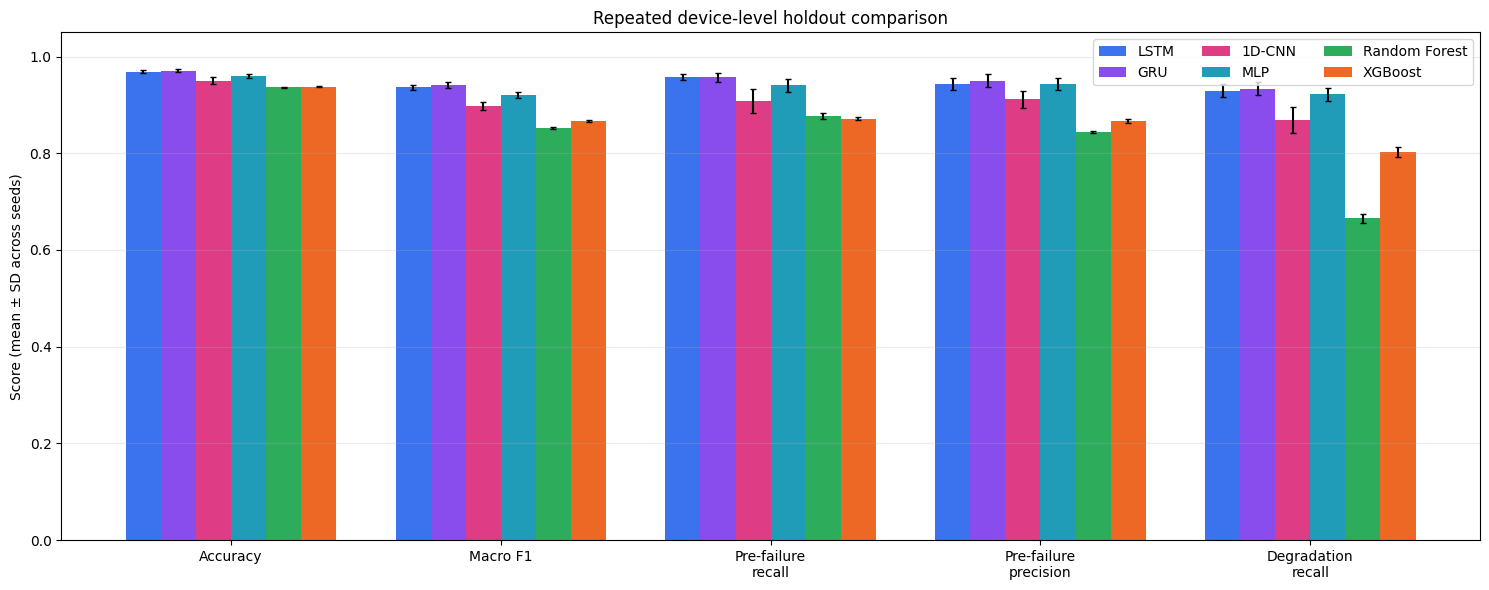

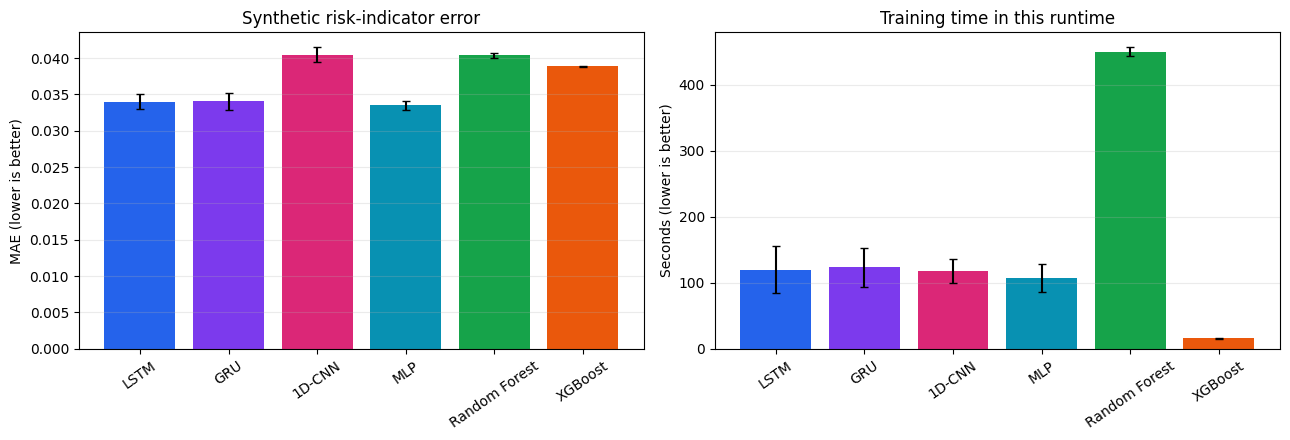

In [13]:
quality_metrics = [
    "accuracy", "macro_f1", "prefail_recall",
    "prefail_precision", "degradation_recall",
]
quality_labels = [
    "Accuracy", "Macro F1", "Pre-failure\nrecall",
    "Pre-failure\nprecision", "Degradation\nrecall",
]
colors = {
    "LSTM": "#2563eb", "GRU": "#7c3aed", "1D-CNN": "#db2777",
    "MLP": "#0891b2", "Random Forest": "#16a34a", "XGBoost": "#ea580c",
}

fig, ax = plt.subplots(figsize=(15, 6))
x = np.arange(len(quality_metrics))
width = 0.13
offsets = (np.arange(len(MODEL_ORDER)) - (len(MODEL_ORDER) - 1) / 2) * width
for offset, model in zip(offsets, MODEL_ORDER):
    means = [summary.loc[model, f"{m}_mean"] for m in quality_metrics]
    stds = [summary.loc[model, f"{m}_std"] for m in quality_metrics]
    ax.bar(
        x + offset, means, width, yerr=stds, capsize=2,
        label=model, color=colors[model], alpha=0.9,
    )
ax.set_xticks(x, quality_labels)
ax.set_ylim(0.0, 1.05)
ax.set_ylabel("Score (mean ± SD across seeds)")
ax.set_title("Repeated device-level holdout comparison")
ax.grid(axis="y", alpha=0.25)
ax.legend(ncol=3)
plt.tight_layout()
fig.savefig(artifact_path("classification_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title, ylabel in [
    (axes[0], "failure_probability_mae", "Synthetic risk-indicator error", "MAE (lower is better)"),
    (axes[1], "train_time_s", "Training time in this runtime", "Seconds (lower is better)"),
]:
    means = [summary.loc[m, f"{metric}_mean"] for m in MODEL_ORDER]
    stds = [summary.loc[m, f"{metric}_std"] for m in MODEL_ORDER]
    ax.bar(
        MODEL_ORDER, means, yerr=stds, capsize=3,
        color=[colors[m] for m in MODEL_ORDER],
    )
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(artifact_path("risk_and_timing.png"), dpi=200, bbox_inches="tight")
plt.show()

### Paired differences with LSTM

These are descriptive differences across seeds on the shared test cohort. A standard
deviation is not a confidence interval or a significance test. Positive classification
differences favor LSTM; negative risk MAE and time differences favor LSTM.

In [14]:
paired_rows = []
for baseline in [m for m in MODEL_ORDER if m != "LSTM"]:
    lstm_rows = runs[runs.model == "LSTM"].set_index("seed")
    base_rows = runs[runs.model == baseline].set_index("seed")
    row = {"baseline": baseline}
    for metric in METRIC_COLUMNS:
        differences = lstm_rows[metric] - base_rows[metric]
        row[f"{metric}_difference_mean"] = differences.mean()
        row[f"{metric}_difference_std"] = differences.std(ddof=1)
    paired_rows.append(row)
paired = pd.DataFrame(paired_rows).set_index("baseline")
display(paired.round(4))
paired.to_csv(artifact_path("paired_lstm_differences.csv"))

,accuracy_difference_mean,accuracy_difference_std,macro_f1_difference_mean,macro_f1_difference_std,weighted_f1_difference_mean,weighted_f1_difference_std,prefail_recall_difference_mean,prefail_recall_difference_std,prefail_precision_difference_mean,prefail_precision_difference_std,degradation_recall_difference_mean,degradation_recall_difference_std,failure_probability_mae_difference_mean,failure_probability_mae_difference_std,train_time_s_difference_mean,train_time_s_difference_std
baseline,,,,,,,,,,,,,,,,
GRU,-0.0025,0.0033,-0.0046,0.0063,-0.0024,0.0032,0.0005,0.0111,-0.0065,0.0150,-0.0041,0.0133,-0.0000,0.0015,-3.4844,24.8242
1D-CNN,0.0182,0.0077,0.0386,0.0097,0.0174,0.0064,0.0492,0.0222,0.0323,0.0125,0.0604,0.0248,-0.0064,0.0012,2.3692,31.9381
MLP,0.0092,0.0038,0.0154,0.0064,0.0085,0.0035,0.0171,0.0084,0.0012,0.0076,0.0073,0.0073,0.0005,0.0016,12.4255,51.0927
Random Forest,0.0323,0.0031,0.0836,0.0053,0.0352,0.0031,0.0805,0.0097,0.0996,0.0120,0.2639,0.0153,-0.0064,0.0010,-330.0554,39.5915
XGBoost,0.0309,0.0032,0.0701,0.0055,0.0300,0.0030,0.0866,0.0063,0.0765,0.0120,0.1276,0.0161,-0.0049,0.0011,103.9581,36.3525


## 8. Diagnostic plots generated from the actual runs

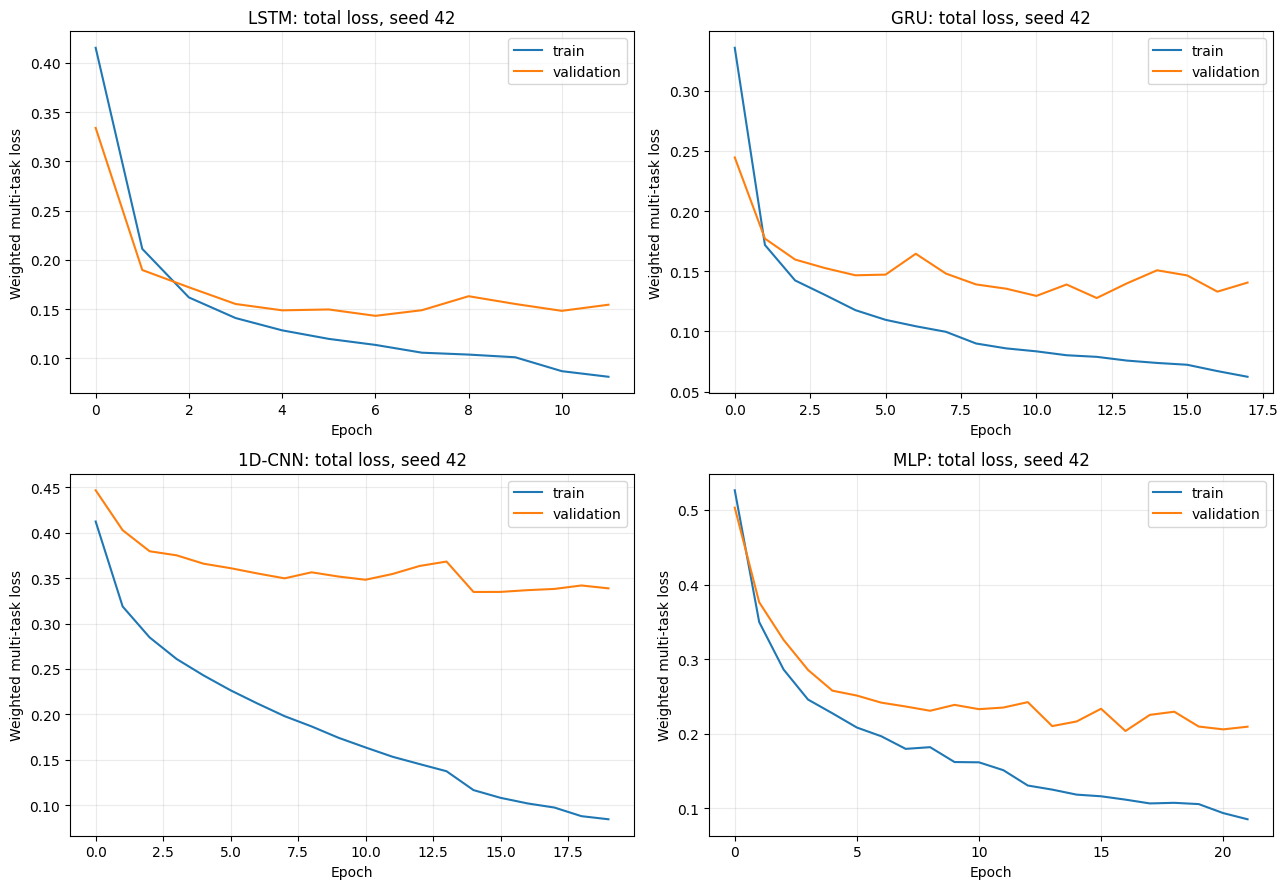

In [15]:
# Representative learning curves (first seed only); aggregate results above remain primary.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, kind in zip(axes.ravel(), NEURAL_MODELS):
    history = histories[kind]
    ax.plot(history["loss"], label="train")
    ax.plot(history["val_loss"], label="validation")
    ax.set_title(f"{kind}: total loss, seed {SEEDS[0]}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted multi-task loss")
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
fig.savefig(artifact_path("learning_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

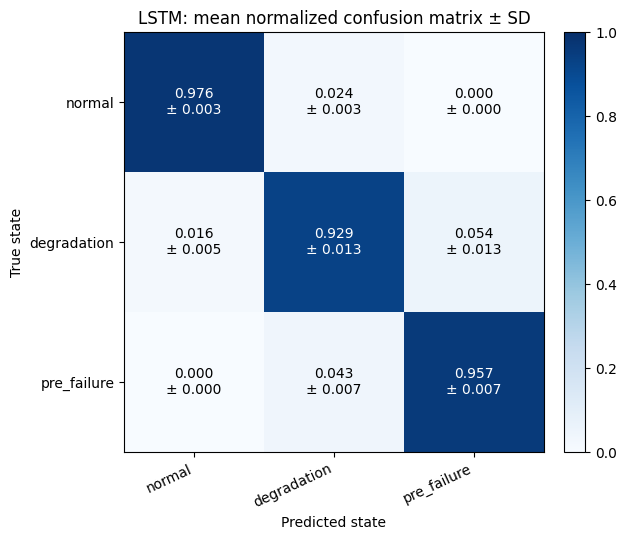

In [16]:
# Mean row-normalized LSTM confusion matrix across repeats, with between-seed SD.
lstm_cms = np.stack(confusion_matrices["LSTM"])
cm_mean = lstm_cms.mean(axis=0)
cm_std = lstm_cms.std(axis=0, ddof=1)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(cm_mean, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        color = "white" if cm_mean[i, j] > 0.55 else "black"
        ax.text(
            j, i, f"{cm_mean[i, j]:.3f}\n± {cm_std[i, j]:.3f}",
            ha="center", va="center", color=color,
        )
ax.set_xticks(range(3), LABELS, rotation=25, ha="right")
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted state")
ax.set_ylabel("True state")
ax.set_title("LSTM: mean normalized confusion matrix ± SD")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(artifact_path("lstm_confusion_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

## 9. Interpretation and manuscript alignment

Report mean ± sample SD from the new run. Five seeds address the reviewer's repetition
request; GRU, CNN, and MLP address the neural-baseline request. No model is guaranteed to
win. These are comparisons of fixed configurations and representations, not a matched
hyperparameter-search study or proof that recurrence alone causes any improvement.

For the supplied dataset at H=0: train/validation/test windows are 36,924 / 6,516 / 10,860.
The test set is identical across repeats. Standardization and class weights use only each
repeat's 204 training devices. Training/validation windows within a device overlap; never
treat windows as statistically independent devices.

The paper's existing 96.99% accuracy, 93.94% macro F1, 0.0343 MAE, per-class scores,
threshold-rule results, curves, and fixed epoch counts refer to an older experiment.
Replace them only with measured results from this protocol. The H=5 results previously
generated use a different task and different split and must remain separately labeled.

No physical sampling interval or observed failure events are present in this CSV.
Treat failure_probability as a normalized synthetic risk indicator. Real failure-risk
calibration and real-device generalization cannot be established with this dataset alone.
Large fault-related readings are not automatically removed as outliers.

The numerical thresholds and implementation of the paper's threshold-rule baseline are
missing. Do not reuse its old scores beside this new experiment without rerunning it.

## 10. Export the first seed's evaluated LSTM checkpoint

Seed selection is fixed in advance (`SEEDS[0]`), independent of test rankings. The saved
checkpoint already contains the best validation weights. Export copies these weights
into an unrolled inference model and reuses that seed's scaler. No additional training,
epoch selection, or scaler refitting occurs. Keras inference equivalence is verified.

TFLite is evaluated over **every test window**, with per-head numerical error and task
metrics recorded. This validates desktop conversion, not ESP32-S3 memory, timing,
operator support, or power use. Dynamic-range optimization is not full-int8 deployment.

In [17]:
EXPORT_SEED = SEEDS[0]
arrays, reconstructed_scaler, export_split = prepare_split(df, EXPORT_SEED)
X_final_test, y_final_test_state, y_final_test_prob, _ = arrays["test"]
final_scaler = joblib.load(run_directory(EXPORT_SEED, "preprocessing") / "scaler.joblib")
np.testing.assert_allclose(final_scaler.mean_, reconstructed_scaler.mean_)
np.testing.assert_allclose(final_scaler.scale_, reconstructed_scaler.scale_)
source_model = keras.models.load_model(
    run_directory(EXPORT_SEED, "LSTM") / "checkpoint.keras", compile=False
)
source_state_prob, source_risk = unpack_prediction(
    source_model.predict(X_final_test, batch_size=BATCH_SIZE, verbose=0)
)
with tf.device("/CPU:0"):
    final_model = build_neural_model("LSTM", unroll_lstm=True)
    final_model.set_weights(source_model.get_weights())
    export_state_prob, export_risk = unpack_prediction(
        final_model.predict(X_final_test, batch_size=BATCH_SIZE, verbose=0)
    )
np.testing.assert_allclose(export_state_prob, source_state_prob, atol=1e-5, rtol=1e-4)
np.testing.assert_allclose(export_risk, source_risk, atol=1e-5, rtol=1e-4)
final_metrics = score_predictions(
    y_final_test_state, export_state_prob.argmax(axis=1), y_final_test_prob, export_risk
)
saved_metrics = runs[(runs.seed == EXPORT_SEED) & (runs.model == "LSTM")].iloc[0]
for metric in METRIC_COLUMNS:
    if metric != "train_time_s":
        # Tiny fused/unrolled differences may change a near-tied classification.
        tolerance = 1e-6 if metric == "failure_probability_mae" else 1e-3
        if abs(final_metrics[metric] - saved_metrics[metric]) > tolerance:
            raise RuntimeError(f"Checkpoint/export score mismatch: {metric}")
save_predictions(run_directory(EXPORT_SEED, "LSTM_export"), arrays, export_state_prob, export_risk)
print("Checkpoint and export Keras predictions agree; no retraining performed.")
display(pd.Series(final_metrics).to_frame("exported_keras_score"))

Checkpoint and export Keras predictions agree; no retraining performed.


,exported_keras_score
accuracy,0.965009
macro_f1,0.929697
weighted_f1,0.966055
prefail_recall,0.965342
prefail_precision,0.926948
degradation_recall,0.914218
failure_probability_mae,0.035178


In [18]:
final_model.save(artifact_path("ddm_lstm_final.keras"))
preprocessing = {
    "features_in_order": FEATURES, "mean": final_scaler.mean_.tolist(),
    "scale": final_scaler.scale_.tolist(), "window": WINDOW, "forecast_horizon": HORIZON,
    "state_labels": dict(enumerate(LABELS)), "export_seed": EXPORT_SEED,
    "training_devices": export_split["train_devices"],
    "validation_devices": export_split["validation_devices"],
    "test_devices": export_split["test_devices"], "dataset_sha256": DATA_SHA256,
    "risk_target_semantics": "synthetic normalized risk indicator, not calibrated failure probability",
    "delta_rule": "current minus preceding raw reading within device; zero only at device start",
}
artifact_path("ddm_preprocessing.json").write_text(json.dumps(preprocessing, indent=2))
TFLITE_PATH = None
conversion_report = {"status": "not_requested", "esp32_validated": False}
if RUN_TFLITE_EXPORT:
    try:
        with tf.device("/CPU:0"):
            converter = tf.lite.TFLiteConverter.from_keras_model(final_model)
            converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
            converter.optimizations = [tf.lite.Optimize.DEFAULT]
            tflite_bytes = converter.convert()
        interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
        inp = interpreter.get_input_details()[0]
        interpreter.resize_tensor_input(inp["index"], [1, WINDOW, len(FEATURES)])
        interpreter.allocate_tensors()
        inp = interpreter.get_input_details()[0]
        if inp["dtype"] != np.float32:
            raise RuntimeError("Export validation currently expects float32 input.")
        details = interpreter.get_output_details()
        state_out = [d for d in details if tuple(d["shape"]) == (1, 3)]
        risk_out = [d for d in details if tuple(d["shape"]) == (1, 1)]
        if len(state_out) != 1 or len(risk_out) != 1:
            raise RuntimeError("Cannot unambiguously identify the two TFLite output heads.")
        lite_state, lite_risk = [], []
        for sample in X_final_test:
            interpreter.set_tensor(inp["index"], sample[None].astype(np.float32))
            interpreter.invoke()
            lite_state.append(interpreter.get_tensor(state_out[0]["index"])[0])
            lite_risk.append(float(interpreter.get_tensor(risk_out[0]["index"])[0, 0]))
        lite_state = np.asarray(lite_state)
        lite_risk = np.asarray(lite_risk)
        lite_metrics = score_predictions(
            y_final_test_state, lite_state.argmax(axis=1), y_final_test_prob, lite_risk
        )
        finite = bool(np.isfinite(lite_state).all() and np.isfinite(lite_risk).all())
        agreement = float(np.mean(lite_state.argmax(axis=1) == export_state_prob.argmax(axis=1)))
        risk_max_error = float(np.max(np.abs(lite_risk - export_risk)))
        # Prespecified engineering tolerances; report every value even when they fail.
        passed = (finite and agreement >= 0.99 and risk_max_error <= 0.02
                  and abs(lite_metrics["macro_f1"] - final_metrics["macro_f1"]) <= 0.005
                  and lite_metrics["failure_probability_mae"] <= final_metrics["failure_probability_mae"] + 0.002)
        candidate = artifact_path("ddm_lstm_builtin_only.tflite" if passed else "ddm_lstm_UNVALIDATED.tflite")
        candidate.write_bytes(tflite_bytes)
        conversion_report = {
            "status": "passed" if passed else "numerical_validation_failed",
            "test_windows": len(X_final_test), "bytes": len(tflite_bytes),
            "class_agreement": agreement, "risk_max_absolute_difference": risk_max_error,
            "class_probability_max_absolute_difference": float(np.max(abs(lite_state - export_state_prob))),
            "keras_metrics": final_metrics, "tflite_metrics": lite_metrics,
            "input": {"name": inp["name"], "dtype": str(inp["dtype"]), "shape": inp["shape"].tolist()},
            "outputs": {"state": state_out[0]["name"], "risk": risk_out[0]["name"]},
            "esp32_validated": False,
        }
        save_predictions(run_directory(EXPORT_SEED, "LSTM_tflite"), arrays, lite_state, lite_risk)
        if passed:
            TFLITE_PATH = candidate
        print("TFLite numerical validation:", conversion_report["status"])
        display(pd.DataFrame({"Keras": final_metrics, "TFLite": lite_metrics}))
    except Exception as exc:
        conversion_report = {"status": "conversion_or_validation_failed", "error": str(exc),
                             "error_type": type(exc).__name__, "esp32_validated": False}
        print("TFLite export could not be validated:", type(exc).__name__, str(exc))
artifact_path("export_validation.json").write_text(json.dumps(conversion_report, indent=2))

Saved artifact at '/tmp/tmp0ep1ie7s'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 20, 9), dtype=tf.float32, name='ddm_sequence')
Output Type:
  Dict[['state', TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)], ['failure_prob', TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)]]
Captures:
  135102288428304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288427536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288428112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288427920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288427344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288419856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288425040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288423888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135102288423696: TensorSpec(shape=(), dtype=tf.resource, name=None)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite numerical validation: passed


,Keras,TFLite
accuracy,0.965009,0.965285
macro_f1,0.929697,0.930514
weighted_f1,0.966055,0.966331
prefail_recall,0.965342,0.965342
prefail_precision,0.926948,0.929211
degradation_recall,0.914218,0.916600
failure_probability_mae,0.035178,0.035180


1162

## 11. Bundle and download reproducibility artifacts

In [19]:
import zipfile

configuration = {
    "protocol": "fixed outer test, repeated device-grouped development splits",
    "dataset_sha256": DATA_SHA256, "window": WINDOW, "horizon": HORIZON,
    "outer_seed": OUTER_SPLIT_SEED, "repeat_seeds": SEEDS,
    "test_fraction": TEST_FRACTION, "validation_fraction_of_development": VALIDATION_FRACTION_OF_DEVELOPMENT,
    "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE, "lr_patience": LR_PATIENCE,
    "rf_trees": RF_TREES, "xgb_trees": XGB_TREES, "deterministic_ops": DETERMINISTIC_OPS,
    "python": sys.version, "platform": platform.platform(),
    "tensorflow": tf.__version__, "keras": keras.__version__,
    "sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
    "numpy": np.__version__, "pandas": pd.__version__,
    "devices": [str(d) for d in tf.config.list_physical_devices()],
    "test_data_reused_across_seeds": True,
}
artifact_path("experiment_config.json").write_text(json.dumps(configuration, indent=2))
# Recreate the paper's per-class table as mean ± SD across repeats, not pooled windows.
class_rows = []
for seed in SEEDS:
    for model_name in MODEL_ORDER:
        table = pd.read_csv(run_directory(seed, model_name) / "per_class_metrics.csv")
        table["seed"] = seed
        table["model"] = model_name
        class_rows.append(table)
class_runs = pd.concat(class_rows, ignore_index=True)
class_runs.to_csv(artifact_path("per_class_all_runs.csv"), index=False)
class_runs.groupby(["model", "class"])[["precision", "recall", "f1"]].agg(
    ["mean", "std"]
).to_csv(artifact_path("per_class_mean_std.csv"))
bundle_path = ARTIFACT_DIR.parent / (ARTIFACT_DIR.name + ".zip")
with zipfile.ZipFile(bundle_path, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(ARTIFACT_DIR.rglob("*")):
        if path.is_file():
            bundle.write(path, arcname=str(path.relative_to(ARTIFACT_DIR)))
print("Bundle:", bundle_path)
print("Keep experiment_config.json with the results. Check export_validation.json before deployment.")
try:
    from google.colab import files
    files.download(str(bundle_path))
except ImportError:
    print("Local run: the ZIP is available at the path above.")

Bundle: /content/ddm_results_h0_20261004T192155Z_3e3033b2.zip
Keep experiment_config.json with the results. Check export_validation.json before deployment.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>